# Task 2 – Machine Learning Model

## Customer Segmentation Using K-Means and Agglomerative Clustering

**Internship:** SWYNEX Technologies

**Dataset:** Mall Customers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("All libraries imported successfully!")

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
df = pd.read_csv("Mall_Customers_Preprocessed.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:", df.shape)

Dataset loaded successfully!

First 5 Records:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0



Dataset Shape: (200, 4)


In [ ]:
X = df.copy()

print("Features selected for K-Means clustering:")
display(X.head())

print("\nDataset Shape:", X.shape)

Features selected for K-Means clustering:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0



Dataset Shape: (200, 4)


In [18]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [19]:
kmeans_labels = kmeans.predict(X)

df["KMeans_Cluster"] = kmeans_labels

print("Customer cluster assignments:")
display(df.head(10))

print("\nNumber of customers in each cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

Customer cluster assignments:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded,KMeans_Cluster
0,-1.424569,-1.738999,-0.434801,1,2
1,-1.281035,-1.738999,1.195704,1,4
2,-1.352802,-1.700830,-1.715913,0,2
3,-1.137502,-1.700830,1.040418,0,4
4,-0.563369,-1.662660,-0.395980,0,2
5,-1.209269,-1.662660,1.001596,0,4
6,-0.276302,-1.624491,-1.715913,0,2
7,-1.137502,-1.624491,1.700384,0,4
8,1.804932,-1.586321,-1.832378,1,0
9,-0.635135,-1.586321,0.846310,0,4



Number of customers in each cluster:
KMeans_Cluster
0    58
1    39
2    47
3    34
4    22
Name: count, dtype: int64


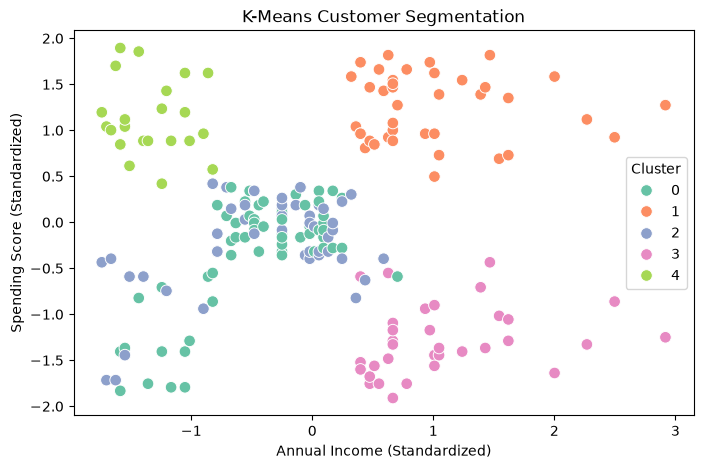

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="Set2",
    s=70
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend(title="Cluster")
plt.show()

In [21]:
kmeans_silhouette = silhouette_score(X, kmeans_labels)

kmeans_db = davies_bouldin_score(X, kmeans_labels)

kmeans_ch = calinski_harabasz_score(X, kmeans_labels)

print("K-Means Model Evaluation")
print("------------------------")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Score:", round(kmeans_db, 4))
print("Calinski-Harabasz Score:", round(kmeans_ch, 4))

K-Means Model Evaluation
------------------------
Silhouette Score: 0.3498
Davies-Bouldin Score: 1.0245
Calinski-Harabasz Score: 97.2583


# Model 2 – Agglomerative Clustering

Agglomerative Clustering is a hierarchical unsupervised machine learning algorithm that groups similar customers into clusters.

In [1]:
from sklearn.cluster import AgglomerativeClustering

print("Agglomerative Clustering imported successfully!")

Agglomerative Clustering imported successfully!


In [2]:
from sklearn.cluster import AgglomerativeClustering

print("Agglomerative Clustering imported successfully!")


Agglomerative Clustering imported successfully!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

df = pd.read_csv("Mall_Customers_Preprocessed.csv")

X = df.copy()

print("Dataset loaded successfully!")
print("Dataset Shape:", X.shape)

Dataset loaded successfully!
Dataset Shape: (200, 4)


In [7]:
agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X)

print("Agglomerative Clustering model trained successfully!")

Agglomerative Clustering model trained successfully!


In [8]:
df["Agglomerative_Cluster"] = agg_labels

print("Customer cluster assignments:")
display(df.head(10))

print("\nNumber of customers in each cluster:")
print(df["Agglomerative_Cluster"].value_counts().sort_index())

Customer cluster assignments:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded,Agglomerative_Cluster
0,-1.424569,-1.738999,-0.434801,1,4
1,-1.281035,-1.738999,1.195704,1,0
2,-1.352802,-1.700830,-1.715913,0,4
3,-1.137502,-1.700830,1.040418,0,0
4,-0.563369,-1.662660,-0.395980,0,4
5,-1.209269,-1.662660,1.001596,0,0
6,-0.276302,-1.624491,-1.715913,0,4
7,-1.137502,-1.624491,1.700384,0,0
8,1.804932,-1.586321,-1.832378,1,4
9,-0.635135,-1.586321,0.846310,0,0



Number of customers in each cluster:
Agglomerative_Cluster
0    58
1    50
2    33
3    39
4    20
Name: count, dtype: int64


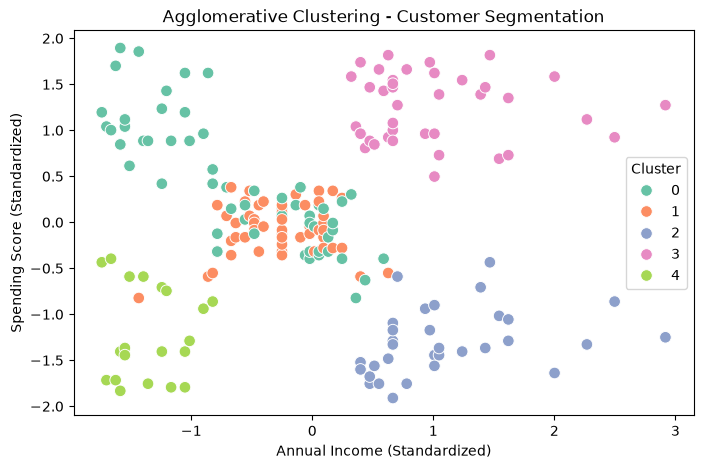

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Agglomerative_Cluster",
    palette="Set2",
    s=70
)

plt.title("Agglomerative Clustering - Customer Segmentation")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend(title="Cluster")
plt.show()

In [10]:
agg_silhouette = silhouette_score(X, agg_labels)

agg_db = davies_bouldin_score(X, agg_labels)

agg_ch = calinski_harabasz_score(X, agg_labels)

print("Agglomerative Clustering Evaluation")
print("-----------------------------------")
print("Silhouette Score:", round(agg_silhouette, 4))
print("Davies-Bouldin Score:", round(agg_db, 4))
print("Calinski-Harabasz Score:", round(agg_ch, 4))

Agglomerative Clustering Evaluation
-----------------------------------
Silhouette Score: 0.3478
Davies-Bouldin Score: 1.0686
Calinski-Harabasz Score: 91.2778


# Model Comparison

In this section, we compare the performance of K-Means and Agglomerative Clustering using three evaluation metrics.

In [13]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

print("K-Means cluster labels restored successfully!")

K-Means cluster labels restored successfully!


In [14]:
kmeans_silhouette = silhouette_score(X, kmeans_labels)
kmeans_db = davies_bouldin_score(X, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X, kmeans_labels)

print("K-Means Evaluation Scores")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Score:", round(kmeans_db, 4))
print("Calinski-Harabasz Score:", round(kmeans_ch, 4))

K-Means Evaluation Scores
Silhouette Score: 0.3498
Davies-Bouldin Score: 1.0245
Calinski-Harabasz Score: 97.2583


In [15]:
comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Score",
        "Calinski-Harabasz Score"
    ],
    "K-Means": [
        kmeans_silhouette,
        kmeans_db,
        kmeans_ch
    ],
    "Agglomerative": [
        agg_silhouette,
        agg_db,
        agg_ch
    ]
})

print("Model Performance Comparison:")
display(comparison.round(4))

Model Performance Comparison:


,Metric,K-Means,Agglomerative
0,Silhouette Score,0.3498,0.3478
1,Davies-Bouldin Score,1.0245,1.0686
2,Calinski-Harabasz Score,97.2583,91.2778


## Conclusion

In this task, two unsupervised machine learning algorithms, K-Means Clustering and Agglomerative Clustering, were trained using the Mall Customers dataset.

Both models grouped 200 customers into five clusters based on Age, Annual Income, Spending Score, and Gender.

The models were evaluated using three metrics: Silhouette Score, Davies-Bouldin Score, and Calinski-Harabasz Score.

K-Means achieved a Silhouette Score of 0.3498, a Davies-Bouldin Score of 1.0245, and a Calinski-Harabasz Score of 97.2583.

Agglomerative Clustering achieved a Silhouette Score of 0.3478, a Davies-Bouldin Score of 1.0686, and a Calinski-Harabasz Score of 91.2778.

Based on these results, K-Means performed slightly better than Agglomerative Clustering.

Therefore, K-Means was selected as the better-performing model for this customer segmentation task.

In [16]:
comparison.to_csv("Task_2_Model_Comparison.csv", index=False)

df.to_csv("Task_2_Clustered_Customers.csv", index=False)

print("Task 2 results saved successfully!")

Task 2 results saved successfully!
